# ADS-B transmitter identification

This notebook combines every `data/*.npy` RFSoC capture. ICAO is used only as the target label. Models receive samples 0--79 of the fixed ADS-B preamble; the payload starts at sample 80 and is never used as an input.

In [4]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("pyModeS") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyModeS<3"])


In [5]:
from pathlib import Path
import hashlib
import json
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyModeS as pms
import torch
import torch.nn as nn

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import DataLoader, Dataset

CONFIG = {
    "data_dir": Path("data"),
    "file_pattern": "*.npy",
    "min_records_per_class": 6,
    "num_classes": 6,
    "samples_per_class": 30000,
    "sample_rate_hz": 10e6,
    "samples_per_half_symbol": 5,
    "preamble_half_symbols": 16,
    "record_len": 1200,
    "preamble_len": 80,
    "payload_start": 80,
    "folds": 5,
    "seed": 42,
    "batch_size": 64,
    "epochs": 15,
    "learning_rate": 1e-3,
    "weight_decay": 2e-4,
    "dropout": 0.30,
    "cnn_channels": (16, 32, 48),
    "tcn_channels": 24,
    "gru_hidden": 32,
    "random_forest_trees": 200,
    "output_dir": Path("results/20261019_adsb_specific_transmitter_mawson_lakes_class_balanced_HARDWARE_DETECTION_6x30000"),
    "figure_dir": Path("results/20261019_adsb_specific_transmitter_mawson_lakes_class_balanced_HARDWARE_DETECTION_6x30000/figures"),
}
CONFIG["output_dir"].mkdir(parents=True, exist_ok=True)
CONFIG["figure_dir"].mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(CONFIG["seed"])
print("Device:", DEVICE)


Device: cpu


## Data


In [6]:
def find_capture_files(data_dir, pattern):
    files = sorted(path.resolve() for path in data_dir.glob(pattern) if path.is_file())
    if not files:
        raise FileNotFoundError(f"No {pattern} files found in {data_dir.resolve()}")
    return files


def decode_record(iq):
    if len(iq) != CONFIG["record_len"]:
        raise ValueError(f"Expected {CONFIG['record_len']} samples, found {len(iq)}")
    halves = np.abs(iq).reshape(-1, CONFIG["samples_per_half_symbol"]).mean(axis=1)
    payload = halves[CONFIG["preamble_half_symbols"]:]
    bits = payload[0::2] > payload[1::2]
    packed = np.packbits(bits).tobytes()
    message = packed.hex().upper()
    payload_hash = hashlib.sha256(packed).hexdigest()
    crc_valid = False
    icao = None
    try:
        crc_valid = int(pms.crc(message)) == 0
        if crc_valid:
            icao = str(pms.adsb.icao(message)).upper()
    except Exception:
        pass
    return icao, payload_hash, crc_valid


def load_capture(path, first_index):
    rows = []
    with path.open("rb") as stream:
        source_index = 0
        while stream.tell() < path.stat().st_size:
            timestamp = pd.Timestamp(np.load(stream, allow_pickle=True).item())
            iq = np.asarray(np.load(stream, allow_pickle=False))
            icao, payload_hash, crc_valid = decode_record(iq)
            preamble = np.asarray(iq[:CONFIG["preamble_len"]], dtype=np.complex64).copy()
            rows.append({
                "record_index": first_index + source_index,
                "source_record_index": source_index,
                "capture_file": path.name,
                "timestamp": timestamp,
                "capture_day": timestamp.strftime("%Y-%m-%d"),
                "sample_count": len(iq),
                "crc_valid": crc_valid,
                "icao": icao,
                "payload_hash": payload_hash,
                "preamble_hash": hashlib.sha256(preamble.tobytes()).hexdigest(),
                "preamble": preamble,
            })
            source_index += 1
    return pd.DataFrame(rows)


files = find_capture_files(CONFIG["data_dir"], CONFIG["file_pattern"])
frames = []
next_index = 0
for path in files:
    frame = load_capture(path, next_index)
    frames.append(frame)
    next_index += len(frame)
records = pd.concat(frames, ignore_index=True)
valid_records = records[records["crc_valid"]].copy()

capture_audit = records.groupby("capture_file", as_index=False).agg(
    total_records=("record_index", "size"),
    crc_valid_records=("crc_valid", "sum"),
    first_timestamp=("timestamp", "min"),
    last_timestamp=("timestamp", "max"),
    embedded_days=("capture_day", "nunique"),
)
file_day_counts = records.groupby(["capture_file", "capture_day"], as_index=False).agg(
    total_records=("record_index", "size"),
    crc_valid_records=("crc_valid", "sum"),
)
day_counts = records.groupby("capture_day", as_index=False).agg(
    total_records=("record_index", "size"),
    crc_valid_records=("crc_valid", "sum"),
    capture_files=("capture_file", "nunique"),
)

all_class_counts = valid_records["icao"].value_counts().sort_index()
eligible_counts = all_class_counts[all_class_counts >= CONFIG["samples_per_class"]]
assert len(eligible_counts) >= CONFIG["num_classes"], "Not enough eligible aircraft"
selected_icaos = eligible_counts.sort_values(ascending=False, kind="stable").head(CONFIG["num_classes"]).index

rng = np.random.default_rng(CONFIG["seed"])
sampled_frames = []
for icao, aircraft in valid_records[valid_records["icao"].isin(selected_icaos)].groupby("icao"):
    day_sizes = aircraft["capture_day"].value_counts().sort_index()
    quotas = CONFIG["samples_per_class"] * day_sizes / day_sizes.sum()
    day_samples = np.floor(quotas).astype(int)
    remainder = CONFIG["samples_per_class"] - int(day_samples.sum())
    extra_days = (quotas - day_samples).sort_values(ascending=False, kind="stable").index[:remainder]
    day_samples.loc[extra_days] += 1
    for day, day_records in aircraft.groupby("capture_day"):
        sampled_frames.append(day_records.sample(n=int(day_samples.loc[day]), replace=False, random_state=rng))
selected = pd.concat(sampled_frames).sort_index().reset_index(drop=True)
retained_counts = selected["icao"].value_counts().sort_index()
class_names = sorted(retained_counts.index)
assert selected["icao"].nunique() == CONFIG["num_classes"]
assert retained_counts.eq(CONFIG["samples_per_class"]).all()
assert len(selected) == CONFIG["num_classes"] * CONFIG["samples_per_class"]
smallest_class = retained_counts.idxmin()
largest_class = retained_counts.idxmax()

aircraft_counts = selected["icao"].value_counts().sort_index().rename("records").to_frame()
aircraft_file_counts = pd.crosstab(selected["icao"], selected["capture_file"]).reindex(class_names)
aircraft_day_counts = pd.crosstab(selected["icao"], selected["capture_day"]).reindex(class_names)
days_per_aircraft = (aircraft_day_counts > 0).sum(axis=1)
selected["appears_multiple_days"] = selected["icao"].map(days_per_aircraft.gt(1))

payload_sizes = valid_records.groupby(["icao", "payload_hash"]).size().rename("copies")
repeated_payload_summary = pd.DataFrame([{
    "unique_payloads": int(len(payload_sizes)),
    "repeated_payload_groups": int((payload_sizes > 1).sum()),
    "records_in_repeated_groups": int(payload_sizes[payload_sizes > 1].sum()),
    "duplicate_copies_beyond_first": int((payload_sizes - 1).clip(lower=0).sum()),
    "largest_payload_multiplicity": int(payload_sizes.max()),
}])

display(capture_audit)
display(file_day_counts)
display(day_counts)
display(aircraft_counts.sort_values("records", ascending=False))
display(aircraft_file_counts)
display(aircraft_day_counts)
display(repeated_payload_summary)
print(f"Files: {len(files)}")
print(f"Records: {len(records):,}; CRC-valid: {len(valid_records):,}")
print(f"Embedded calendar days: {records['capture_day'].nunique()}")
print(f"ICAO classes: {valid_records['icao'].nunique()}; retained classes: {len(class_names)}")
print(f"Retained records: {len(selected):,}")
print(f"Smallest retained class: {smallest_class} ({retained_counts.min():,})")
print(f"Largest retained class: {largest_class} ({retained_counts.max():,})")
print(f"Retained aircraft seen on multiple days: {days_per_aircraft.gt(1).sum():,}")

,capture_file,total_records,crc_valid_records,first_timestamp,last_timestamp,embedded_days
0,061026_ML_HARDWARE_DETECTION.npy,141905,137135,2026-10-06 17:22:26.224275,2026-10-09 15:21:51.400855,4
1,091026_ML_HARDWARE_DETECTION.npy,33703,32431,2026-10-09 17:57:50.832207,2026-10-12 10:12:43.004159,4
2,141026_ML_HARDWARE_DETECTION.npy,87488,84743,2026-10-14 18:10:22.755735,2026-10-15 09:00:42.487557,2
3,151026_ML_HARDWARE_DETECTION.npy,802248,771652,2026-10-15 17:50:10.673199,2026-10-19 09:57:42.835756,5


,capture_file,capture_day,total_records,crc_valid_records
0,061026_ML_HARDWARE_DETECTION.npy,2026-10-06,12843,12484
1,061026_ML_HARDWARE_DETECTION.npy,2026-10-07,52812,50917
2,061026_ML_HARDWARE_DETECTION.npy,2026-10-08,44532,42976
3,061026_ML_HARDWARE_DETECTION.npy,2026-10-09,31718,30758
4,091026_ML_HARDWARE_DETECTION.npy,2026-10-09,435,425
5,091026_ML_HARDWARE_DETECTION.npy,2026-10-10,14564,14003
6,091026_ML_HARDWARE_DETECTION.npy,2026-10-11,11534,11042
7,091026_ML_HARDWARE_DETECTION.npy,2026-10-12,7170,6961
8,141026_ML_HARDWARE_DETECTION.npy,2026-10-14,48821,47277
9,141026_ML_HARDWARE_DETECTION.npy,2026-10-15,38667,37466


,capture_day,total_records,crc_valid_records,capture_files
0,2026-10-06,12843,12484,1
1,2026-10-07,52812,50917,1
2,2026-10-08,44532,42976,1
3,2026-10-09,32153,31183,2
4,2026-10-10,14564,14003,1
5,2026-10-11,11534,11042,1
6,2026-10-12,7170,6961,1
7,2026-10-14,48821,47277,1
8,2026-10-15,113477,109707,2
9,2026-10-16,290053,279468,1


,records
icao,
7C0077,30000
7C444D,30000
7C7144,30000
7C79B4,30000
7C7B5F,30000
7C7B61,30000


capture_file,061026_ML_HARDWARE_DETECTION.npy,091026_ML_HARDWARE_DETECTION.npy,141026_ML_HARDWARE_DETECTION.npy,151026_ML_HARDWARE_DETECTION.npy
icao,,,,
7C0077,717,2144,76,27063
7C444D,2094,2019,0,25887
7C7144,2290,797,6812,20101
7C79B4,1336,161,0,28503
7C7B5F,1613,158,8463,19766
7C7B61,5773,135,0,24092


capture_day,2026-10-06,2026-10-07,2026-10-08,2026-10-09,2026-10-10,2026-10-11,2026-10-12,2026-10-14,2026-10-15,2026-10-16,2026-10-17,2026-10-18,2026-10-19
icao,,,,,,,,,,,,,
7C0077,182,535,0,0,944,512,688,76,2905,7873,10106,6023,156
7C444D,0,76,816,1202,1007,1012,0,0,0,11735,7712,6440,0
7C7144,0,809,244,1237,5,792,0,6812,5675,6656,7770,0,0
7C79B4,597,739,0,0,12,149,0,0,2232,9917,11095,5259,0
7C7B5F,0,732,219,662,0,158,0,5291,4298,9911,3677,4684,368
7C7B61,0,2331,3442,0,6,129,0,0,7191,2251,12574,2076,0


,unique_payloads,repeated_payload_groups,records_in_repeated_groups,duplicate_copies_beyond_first,largest_payload_multiplicity
0,725530,55852,356283,300431,4196


Files: 4
Records: 1,065,344; CRC-valid: 1,025,961
Embedded calendar days: 13
ICAO classes: 437; retained classes: 6
Retained records: 180,000
Smallest retained class: 7C0077 (30,000)
Largest retained class: 7C0077 (30,000)
Retained aircraft seen on multiple days: 6


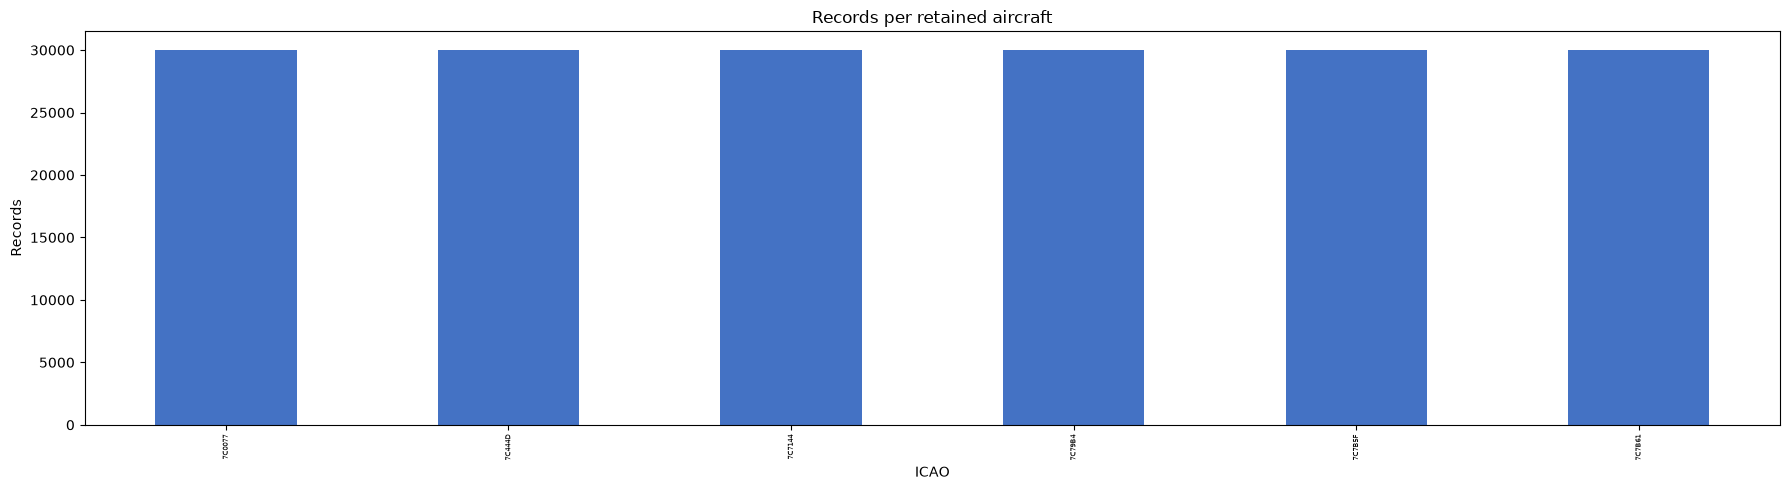

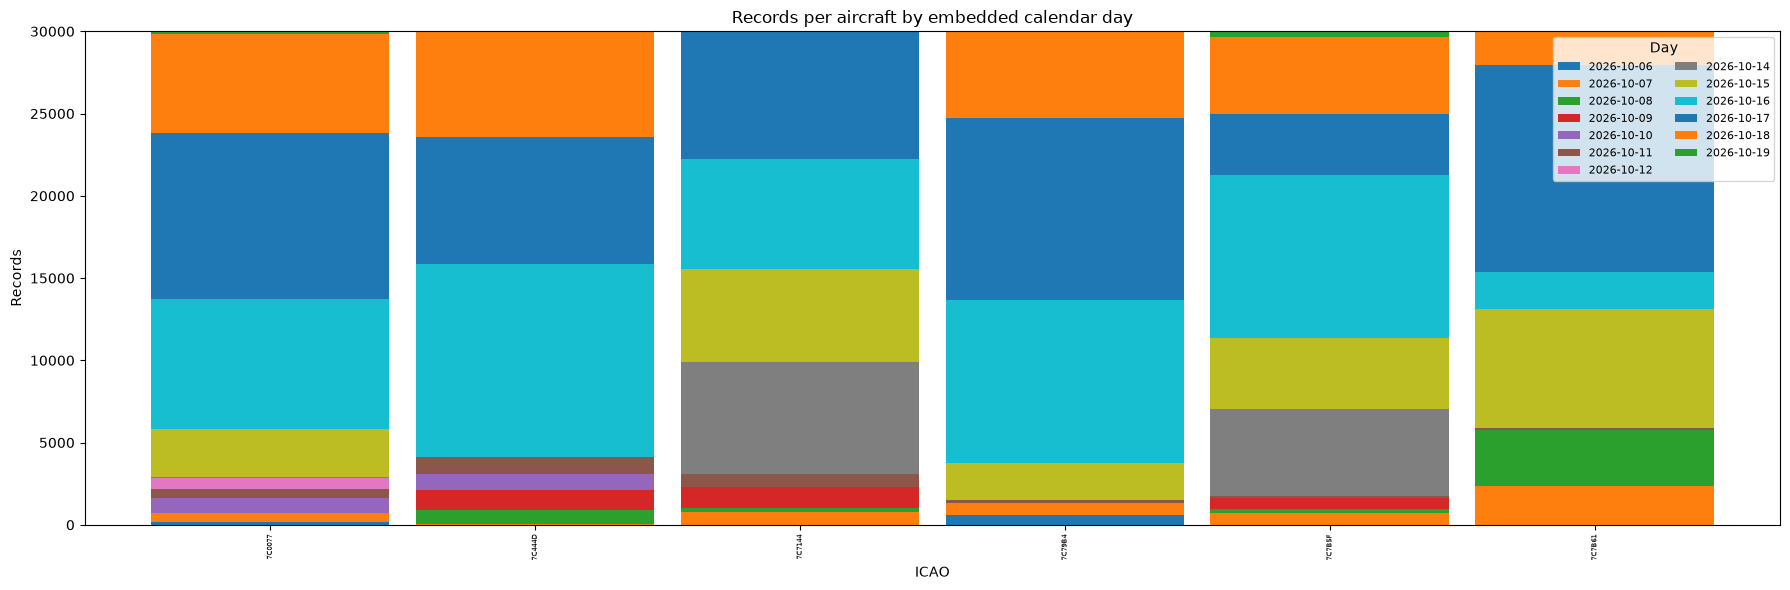

In [7]:
ordered = aircraft_counts["records"].sort_values(ascending=False)

fig, axis = plt.subplots(figsize=(18, 5))
ordered.plot(kind="bar", ax=axis, color="#4472C4")
axis.set(title="Records per retained aircraft", xlabel="ICAO", ylabel="Records")
axis.tick_params(axis="x", labelsize=5)
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "records_per_aircraft.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axis = plt.subplots(figsize=(18, 6))
aircraft_day_counts.loc[ordered.index].plot(kind="bar", stacked=True, ax=axis, width=0.9)
axis.set(title="Records per aircraft by embedded calendar day", xlabel="ICAO", ylabel="Records")
axis.tick_params(axis="x", labelsize=5)
axis.legend(title="Day", fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "records_by_day.png", dpi=180, bbox_inches="tight")
plt.show()



## Preamble inputs


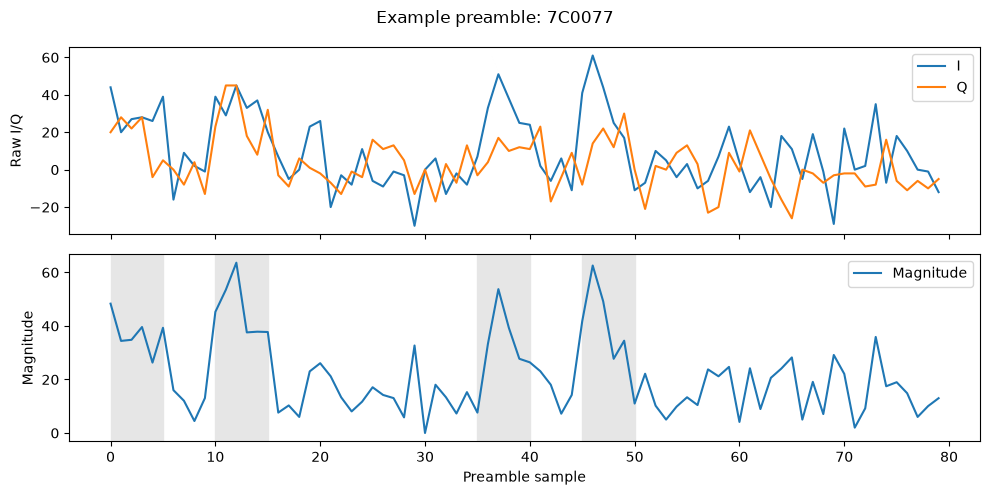

I/Q input: (180000, 2, 80)
Physical features: (180000, 33)
Input samples: 0--79; payload samples used: 0


In [8]:
PULSE_HALVES = np.zeros(CONFIG["preamble_half_symbols"], dtype=bool)
ACTIVE_HALF_INDICES = np.array([0, 2, 7, 9])
PULSE_HALVES[ACTIVE_HALF_INDICES] = True
ACTIVE_MASK = np.repeat(PULSE_HALVES, CONFIG["samples_per_half_symbol"])


def moment_features(values):
    values = np.asarray(values, dtype=np.float64)
    mean = values.mean()
    std = values.std() + 1e-12
    z = (values - mean) / std
    return mean, std, np.mean(z ** 3), np.mean(z ** 4)


def preamble_features(preamble):
    active = preamble[ACTIVE_MASK]
    quiet = preamble[~ACTIVE_MASK]
    pulses = np.stack([
        preamble[i * CONFIG["samples_per_half_symbol"]:(i + 1) * CONFIG["samples_per_half_symbol"]]
        for i in ACTIVE_HALF_INDICES
    ])
    amplitude = np.abs(active)
    values = list(moment_features(amplitude))
    phase_steps = np.angle(pulses[:, 1:] * np.conj(pulses[:, :-1])).ravel()
    mean_step = np.angle(np.mean(np.exp(1j * phase_steps)))
    centred_steps = np.angle(np.exp(1j * (phase_steps - mean_step)))
    i_power = np.mean(active.real ** 2) + 1e-12
    q_power = np.mean(active.imag ** 2) + 1e-12
    correlation = np.corrcoef(active.real, active.imag)[0, 1]
    correlation = correlation if np.isfinite(correlation) else 0.0
    prototype = pulses.mean(axis=0)
    pulse_power = np.mean(np.abs(pulses) ** 2, axis=1)
    values += [
        amplitude.max() / (np.sqrt(np.mean(amplitude ** 2)) + 1e-12),
        np.mean(amplitude ** 2),
        np.mean(np.abs(quiet) ** 2),
        10 * np.log10((np.mean(amplitude ** 2) + 1e-12) / (np.mean(np.abs(quiet) ** 2) + 1e-12)),
        mean_step * CONFIG["sample_rate_hz"] / (2 * np.pi),
        np.std(centred_steps),
        10 * np.log10(i_power / q_power),
        correlation,
        np.std(pulse_power) / (np.mean(pulse_power) + 1e-12),
    ]
    values += np.abs(pulses).mean(axis=0).tolist()
    values += prototype.real.tolist()
    values += prototype.imag.tolist()
    values += np.angle(prototype).tolist()
    return np.asarray(values, dtype=np.float32)


FEATURE_NAMES = [
    "amplitude_mean", "amplitude_std", "amplitude_skew", "amplitude_kurtosis",
    "crest_factor", "active_power", "quiet_power", "preamble_snr_db",
    "carrier_offset_hz", "phase_step_std", "iq_power_imbalance_db",
    "iq_correlation", "pulse_power_variation",
]
FEATURE_NAMES += [f"pulse_amplitude_{i}" for i in range(5)]
FEATURE_NAMES += [f"pulse_i_{i}" for i in range(5)]
FEATURE_NAMES += [f"pulse_q_{i}" for i in range(5)]
FEATURE_NAMES += [f"pulse_phase_{i}" for i in range(5)]

class_to_index = {name: index for index, name in enumerate(class_names)}
y = selected["icao"].map(class_to_index).to_numpy()
raw_preambles = np.stack(selected["preamble"].to_numpy()).astype(np.complex64)
source_hashes = selected["preamble_hash"].to_numpy()
stored_hashes = np.array([hashlib.sha256(value.tobytes()).hexdigest() for value in raw_preambles])
assert np.array_equal(source_hashes, stored_hashes)

X_preamble = np.stack([raw_preambles.real, raw_preambles.imag], axis=1).astype(np.float32)
X_physical = np.stack([preamble_features(value) for value in raw_preambles])
model_metadata = selected[[
    "record_index", "source_record_index", "capture_file", "capture_day",
    "timestamp", "icao", "payload_hash", "appears_multiple_days",
]].copy()

assert X_preamble.shape[1:] == (2, 80)
assert X_physical.shape[1] == len(FEATURE_NAMES) == 33
assert CONFIG["preamble_len"] == CONFIG["payload_start"] == 80

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(X_preamble[0, 0], label="I")
axes[0].plot(X_preamble[0, 1], label="Q")
axes[0].set_ylabel("Raw I/Q")
axes[0].legend()
axes[1].plot(np.abs(raw_preambles[0]), label="Magnitude")
for start in ACTIVE_HALF_INDICES * CONFIG["samples_per_half_symbol"]:
    axes[1].axvspan(start, start + CONFIG["samples_per_half_symbol"], color="0.9")
axes[1].set(xlabel="Preamble sample", ylabel="Magnitude")
axes[1].legend()
fig.suptitle(f"Example preamble: {model_metadata.loc[0, 'icao']}")
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "preamble_input.png", dpi=180, bbox_inches="tight")
plt.show()

records.drop(columns="preamble", inplace=True)
valid_records.drop(columns="preamble", inplace=True)
selected.drop(columns="preamble", inplace=True)
print("I/Q input:", X_preamble.shape)
print("Physical features:", X_physical.shape)
print("Input samples: 0--79; payload samples used: 0")


## Five-fold split


,fold,training_records,validation_records,training_classes,validation_classes,record_overlap,payload_hash_overlap
0,1,144000,36000,6,6,0,3110
1,2,144000,36000,6,6,0,3139
2,3,144000,36000,6,6,0,3139
3,4,144000,36000,6,6,0,3154
4,5,144000,36000,6,6,0,3036


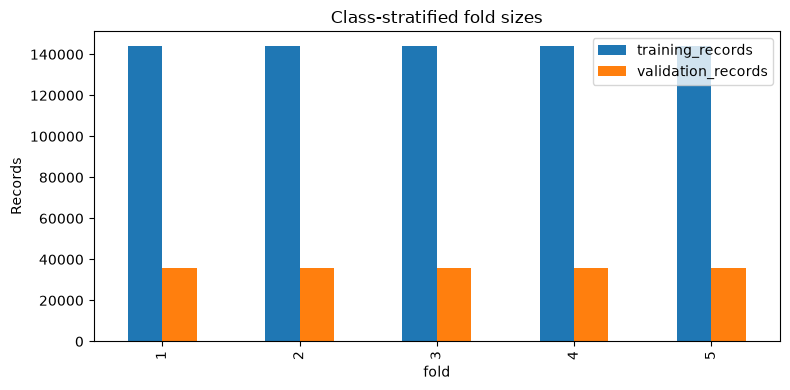

In [9]:
n_splits = min(CONFIG["folds"], int(retained_counts.min()))
splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=CONFIG["seed"])
folds = list(splitter.split(np.zeros(len(y)), y))

fold_rows = []
validation_count = np.zeros(len(y), dtype=int)
for fold_number, (train_index, val_index) in enumerate(folds, 1):
    validation_count[val_index] += 1
    train_hashes = set(model_metadata.loc[train_index, "payload_hash"])
    val_hashes = set(model_metadata.loc[val_index, "payload_hash"])
    assert set(train_index).isdisjoint(val_index)
    assert set(y[train_index]) == set(range(len(class_names)))
    assert set(y[val_index]) == set(range(len(class_names)))
    fold_rows.append({
        "fold": fold_number,
        "training_records": len(train_index),
        "validation_records": len(val_index),
        "training_classes": len(np.unique(y[train_index])),
        "validation_classes": len(np.unique(y[val_index])),
        "record_overlap": 0,
        "payload_hash_overlap": len(train_hashes & val_hashes),
    })
assert np.all(validation_count == 1)
fold_audit = pd.DataFrame(fold_rows)
display(fold_audit)

fig, axis = plt.subplots(figsize=(8, 4))
fold_audit.set_index("fold")[["training_records", "validation_records"]].plot(kind="bar", ax=axis)
axis.set(title="Class-stratified fold sizes", ylabel="Records")
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "fold_sizes.png", dpi=180, bbox_inches="tight")
plt.show()


## Models


In [10]:
class ArrayDataset(Dataset):
    def __init__(self, values, labels=None):
        self.values = torch.as_tensor(values, dtype=torch.float32)
        self.labels = None if labels is None else torch.as_tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.values)

    def __getitem__(self, index):
        if self.labels is None:
            return self.values[index]
        return self.values[index], self.labels[index]


class PreambleCNN(nn.Module):
    def __init__(self, classes):
        super().__init__()
        c1, c2, c3 = CONFIG["cnn_channels"]
        self.network = nn.Sequential(
            nn.Conv1d(2, c1, 7, padding=3), nn.BatchNorm1d(c1), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(c1, c2, 5, padding=2), nn.BatchNorm1d(c2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(c2, c3, 3, padding=1), nn.BatchNorm1d(c3), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(CONFIG["dropout"]),
            nn.Linear(c3, classes),
        )

    def forward(self, values):
        return self.network(values)


class TCNBlock(nn.Module):
    def __init__(self, channels, dilation):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, 3, padding=dilation, dilation=dilation),
            nn.BatchNorm1d(channels), nn.ReLU(), nn.Dropout(CONFIG["dropout"] / 2),
            nn.Conv1d(channels, channels, 3, padding=dilation, dilation=dilation),
            nn.BatchNorm1d(channels),
        )

    def forward(self, values):
        return torch.relu(values + self.block(values))


class PreambleTCN(nn.Module):
    def __init__(self, classes):
        super().__init__()
        channels = CONFIG["tcn_channels"]
        self.input_layer = nn.Conv1d(2, channels, 1)
        self.blocks = nn.Sequential(*(TCNBlock(channels, d) for d in (1, 2, 4)))
        self.output_layer = nn.Sequential(
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(CONFIG["dropout"]),
            nn.Linear(channels, classes),
        )

    def forward(self, values):
        return self.output_layer(self.blocks(self.input_layer(values)))


class PreambleGRU(nn.Module):
    def __init__(self, classes):
        super().__init__()
        self.gru = nn.GRU(2, CONFIG["gru_hidden"], batch_first=True, bidirectional=True)
        self.output_layer = nn.Sequential(
            nn.LayerNorm(2 * CONFIG["gru_hidden"]),
            nn.Dropout(CONFIG["dropout"]),
            nn.Linear(2 * CONFIG["gru_hidden"], classes),
        )

    def forward(self, values):
        _, hidden = self.gru(values.transpose(1, 2))
        return self.output_layer(torch.cat([hidden[-2], hidden[-1]], dim=1))


MODEL_NAMES = {
    "physical_feature_svm": "Physical-feature RBF SVM",
    "physical_feature_random_forest": "Physical-feature random forest",
    "preamble_cnn": "Compact 1D CNN",
    "preamble_tcn": "Compact TCN",
    "preamble_gru_rnn": "Compact bidirectional GRU",
}
MODEL_ORDER = list(MODEL_NAMES)


In [11]:
def loader(values, labels=None, shuffle=False):
    return DataLoader(
        ArrayDataset(values, labels), batch_size=CONFIG["batch_size"],
        shuffle=shuffle, num_workers=0, pin_memory=DEVICE == "cuda",
    )


def train_neural(model, train_values, train_labels, seed):
    set_seed(seed)
    model = model.to(DEVICE)
    counts = np.bincount(train_labels, minlength=len(class_names)).astype(np.float32)
    weights = counts.sum() / (len(class_names) * counts)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, device=DEVICE))
    optimiser = torch.optim.AdamW(
        model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
    )
    history = []
    for _ in range(CONFIG["epochs"]):
        model.train()
        loss_sum = 0.0
        for batch, targets in loader(train_values, train_labels, shuffle=True):
            batch, targets = batch.to(DEVICE), targets.to(DEVICE)
            optimiser.zero_grad()
            loss = criterion(model(batch), targets)
            loss.backward()
            optimiser.step()
            loss_sum += loss.item() * len(targets)
        history.append(loss_sum / len(train_labels))
    return model, history, weights


@torch.no_grad()
def predict_neural(model, values):
    model.eval()
    return np.concatenate([
        torch.argmax(model(batch.to(DEVICE)), dim=1).cpu().numpy()
        for batch in loader(values)
    ])


def scores(targets, predictions):
    return {
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
    }


def svm_size_bytes(model):
    scaler = model.named_steps["standardscaler"]
    svc = model.named_steps["svc"]
    arrays = [scaler.mean_, scaler.scale_, svc.support_vectors_, svc.dual_coef_, svc.intercept_, svc.support_]
    return sum(value.nbytes for value in arrays)


def forest_size_bytes(model):
    attributes = ["children_left", "children_right", "feature", "threshold", "value", "impurity", "n_node_samples"]
    return sum(
        getattr(tree.tree_, name).nbytes
        for tree in model.estimators_
        for name in attributes
    )


## Train and evaluate


In [12]:
fold_results = []
prediction_rows = []
model_size_rows = []
importance_rows = []
preprocessing_rows = []
training_histories = {}

for fold_number, (train_index, val_index) in enumerate(folds, 1):
    print(f"Fold {fold_number}/{n_splits}")
    channel_mean = X_preamble[train_index].mean(axis=(0, 2), keepdims=True)
    channel_std = X_preamble[train_index].std(axis=(0, 2), keepdims=True) + 1e-6
    scaled_train = (X_preamble[train_index] - channel_mean) / channel_std
    scaled_validation = (X_preamble[val_index] - channel_mean) / channel_std
    train_counts = np.bincount(y[train_index], minlength=len(class_names)).astype(np.float32)
    train_weights = train_counts.sum() / (len(class_names) * train_counts)
    preprocessing_rows.append({
        "fold": fold_number,
        "training_records": len(train_index),
        "validation_records": len(val_index),
        "iq_mean_i": float(channel_mean[0, 0, 0]),
        "iq_mean_q": float(channel_mean[0, 1, 0]),
        "iq_std_i": float(channel_std[0, 0, 0]),
        "iq_std_q": float(channel_std[0, 1, 0]),
        "class_weight_min": float(train_weights.min()),
        "class_weight_max": float(train_weights.max()),
        "fit_scope": "training fold only",
    })

    for model_number, experiment in enumerate(MODEL_ORDER):
        seed = CONFIG["seed"] + 100 * fold_number + model_number
        started = time.perf_counter()

        if experiment == "physical_feature_svm":
            model = make_pipeline(
                StandardScaler(),
                SVC(C=3.0, kernel="rbf", gamma="scale", class_weight="balanced"),
            )
            model.fit(X_physical[train_index], y[train_index])
            predictions = model.predict(X_physical[val_index])
            parameters = np.nan
            support_vectors = model.named_steps["svc"].support_vectors_.shape[0]
            tree_nodes = np.nan
            fitted_size_mb = svm_size_bytes(model) / 1e6

        elif experiment == "physical_feature_random_forest":
            model = RandomForestClassifier(
                n_estimators=CONFIG["random_forest_trees"], min_samples_leaf=2,
                max_features="sqrt", class_weight="balanced_subsample",
                n_jobs=-1, random_state=seed,
            )
            model.fit(X_physical[train_index], y[train_index])
            predictions = model.predict(X_physical[val_index])
            for name, importance in zip(FEATURE_NAMES, model.feature_importances_):
                importance_rows.append({"fold": fold_number, "feature": name, "importance": importance})
            parameters = np.nan
            support_vectors = np.nan
            tree_nodes = sum(tree.tree_.node_count for tree in model.estimators_)
            fitted_size_mb = forest_size_bytes(model) / 1e6

        else:
            model_class = {
                "preamble_cnn": PreambleCNN,
                "preamble_tcn": PreambleTCN,
                "preamble_gru_rnn": PreambleGRU,
            }[experiment]
            model = model_class(len(class_names))
            model, history, neural_weights = train_neural(model, scaled_train, y[train_index], seed)
            assert np.allclose(neural_weights, train_weights)
            predictions = predict_neural(model, scaled_validation)
            parameters = sum(parameter.numel() for parameter in model.parameters())
            support_vectors = np.nan
            tree_nodes = np.nan
            fitted_size_mb = parameters * 4 / 1e6
            training_histories[(experiment, fold_number)] = history

        metrics = scores(y[val_index], predictions)
        fold_results.append({
            "experiment": experiment,
            "model": MODEL_NAMES[experiment],
            "fold": fold_number,
            "n_train": len(train_index),
            "n_validation": len(val_index),
            **metrics,
        })
        model_size_rows.append({
            "experiment": experiment,
            "fold": fold_number,
            "parameters": parameters,
            "support_vectors": support_vectors,
            "tree_nodes": tree_nodes,
            "estimated_size_mb": fitted_size_mb,
            "training_seconds": time.perf_counter() - started,
        })
        for position, target, prediction in zip(val_index, y[val_index], predictions):
            meta = model_metadata.loc[position]
            prediction_rows.append({
                "experiment": experiment,
                "fold": fold_number,
                "record_index": int(meta["record_index"]),
                "capture_file": meta["capture_file"],
                "capture_day": meta["capture_day"],
                "appears_multiple_days": bool(meta["appears_multiple_days"]),
                "true_class": class_names[int(target)],
                "predicted_class": class_names[int(prediction)],
            })
        print(f"  {MODEL_NAMES[experiment]:32s} balanced={metrics['balanced_accuracy']:.3f}")

fold_results = pd.DataFrame(fold_results)
predictions = pd.DataFrame(prediction_rows)
model_sizes = pd.DataFrame(model_size_rows)
feature_importance = pd.DataFrame(importance_rows)
preprocessing_audit = pd.DataFrame(preprocessing_rows)


Fold 1/5
  Physical-feature RBF SVM         balanced=0.591
  Physical-feature random forest   balanced=0.577
  Compact 1D CNN                   balanced=0.623
  Compact TCN                      balanced=0.615
  Compact bidirectional GRU        balanced=0.705
Fold 2/5
  Physical-feature RBF SVM         balanced=0.588
  Physical-feature random forest   balanced=0.571
  Compact 1D CNN                   balanced=0.623
  Compact TCN                      balanced=0.615
  Compact bidirectional GRU        balanced=0.722
Fold 3/5
  Physical-feature RBF SVM         balanced=0.593
  Physical-feature random forest   balanced=0.574
  Compact 1D CNN                   balanced=0.611
  Compact TCN                      balanced=0.580
  Compact bidirectional GRU        balanced=0.709
Fold 4/5
  Physical-feature RBF SVM         balanced=0.592
  Physical-feature random forest   balanced=0.576
  Compact 1D CNN                   balanced=0.624
  Compact TCN                      balanced=0.584
  Compact bidi

In [13]:
aggregate_rows = []
class_recall_rows = []
for experiment in MODEL_ORDER:
    subset = predictions[predictions["experiment"] == experiment]
    per_fold = fold_results[fold_results["experiment"] == experiment]
    matrix = confusion_matrix(
        subset["true_class"], subset["predicted_class"], labels=class_names, normalize="true"
    )
    recalls = np.diag(matrix)
    for class_name, recall in zip(class_names, recalls):
        class_recall_rows.append({
            "experiment": experiment,
            "icao": class_name,
            "records": int(retained_counts[class_name]),
            "days": int(days_per_aircraft[class_name]),
            "recall": recall,
        })
    overall = scores(subset["true_class"], subset["predicted_class"])
    sizes = model_sizes[model_sizes["experiment"] == experiment]
    aggregate_rows.append({
        "experiment": experiment,
        "model": MODEL_NAMES[experiment],
        "oof_accuracy": overall["accuracy"],
        "oof_balanced_accuracy": overall["balanced_accuracy"],
        "oof_macro_f1": overall["macro_f1"],
        "fold_accuracy_mean": per_fold["accuracy"].mean(),
        "fold_accuracy_std": per_fold["accuracy"].std(ddof=1),
        "fold_balanced_accuracy_mean": per_fold["balanced_accuracy"].mean(),
        "fold_balanced_accuracy_std": per_fold["balanced_accuracy"].std(ddof=1),
        "fold_macro_f1_mean": per_fold["macro_f1"].mean(),
        "fold_macro_f1_std": per_fold["macro_f1"].std(ddof=1),
        "parameters": sizes["parameters"].dropna().mean(),
        "support_vectors_mean": sizes["support_vectors"].dropna().mean(),
        "tree_nodes_mean": sizes["tree_nodes"].dropna().mean(),
        "estimated_size_mb_mean": sizes["estimated_size_mb"].mean(),
    })

aggregate_results = pd.DataFrame(aggregate_rows).sort_values(
    ["oof_balanced_accuracy", "oof_macro_f1"], ascending=False
).reset_index(drop=True)
class_recall = pd.DataFrame(class_recall_rows)
best_experiment = aggregate_results.loc[0, "experiment"]
best_model = aggregate_results.loc[0, "model"]

cross_day_rows = []
for experiment in MODEL_ORDER:
    subset = predictions[predictions["experiment"] == experiment]
    part = subset[subset["appears_multiple_days"]]
    cross_day_rows.append({
        "experiment": experiment,
        "aircraft_group": "multiple days",
        "classes": part["true_class"].nunique(),
        "records": len(part),
        **(scores(part["true_class"], part["predicted_class"]) if not part.empty else {
            "accuracy": np.nan, "balanced_accuracy": np.nan, "macro_f1": np.nan,
        }),
    })
cross_day_results = pd.DataFrame(cross_day_rows)

display(aggregate_results)
display(fold_results.groupby("model")[["accuracy", "balanced_accuracy", "macro_f1"]].agg(["mean", "std"]))
display(cross_day_results[cross_day_results["experiment"] == best_experiment])
print("Best model by balanced accuracy:", best_model)


,experiment,model,oof_accuracy,oof_balanced_accuracy,oof_macro_f1,fold_accuracy_mean,fold_accuracy_std,fold_balanced_accuracy_mean,fold_balanced_accuracy_std,fold_macro_f1_mean,fold_macro_f1_std,parameters,support_vectors_mean,tree_nodes_mean,estimated_size_mb_mean
0,preamble_gru_rnn,Compact bidirectional GRU,0.707783,0.707783,0.704650,0.707783,0.010494,0.707783,0.010494,0.699802,0.009017,7430.0,NaN,NaN,0.029720
1,preamble_cnn,Compact 1D CNN,0.619472,0.619472,0.618289,0.619472,0.005599,0.619472,0.005599,0.615236,0.006586,7974.0,NaN,NaN,0.031896
2,preamble_tcn,Compact TCN,0.601183,0.601183,0.592458,0.601183,0.017561,0.601183,0.017561,0.586767,0.019632,11022.0,NaN,NaN,0.044088
3,physical_feature_svm,Physical-feature RBF SVM,0.592022,0.592022,0.588194,0.592022,0.003236,0.592022,0.003236,0.588185,0.003452,NaN,108823.2,NaN,33.518194
4,physical_feature_random_forest,Physical-feature random forest,0.574806,0.574806,0.571504,0.574806,0.002385,0.574806,0.002385,0.571501,0.002312,NaN,NaN,9818434.8,942.569741


accuracy           balanced_accuracy  \
                                    mean       std              mean   
model                                                                  
Compact 1D CNN                  0.619472  0.005599          0.619472   
Compact TCN                     0.601183  0.017561          0.601183   
Compact bidirectional GRU       0.707783  0.010494          0.707783   
Physical-feature RBF SVM        0.592022  0.003236          0.592022   
Physical-feature random forest  0.574806  0.002385          0.574806   

                                          macro_f1            
                                     std      mean       std  
model                                                         
Compact 1D CNN                  0.005599  0.615236  0.006586  
Compact TCN                     0.017561  0.586767  0.019632  
Compact bidirectional GRU       0.010494  0.699802  0.009017  
Physical-feature RBF SVM        0.003236  0.588185  0.003452  
Physical-feature random forest  0.002385  0.571501  0.002312

,experiment,aircraft_group,classes,records,accuracy,balanced_accuracy,macro_f1
4,preamble_gru_rnn,multiple days,6,180000,0.707783,0.707783,0.70465


Best model by balanced accuracy: Compact bidirectional GRU


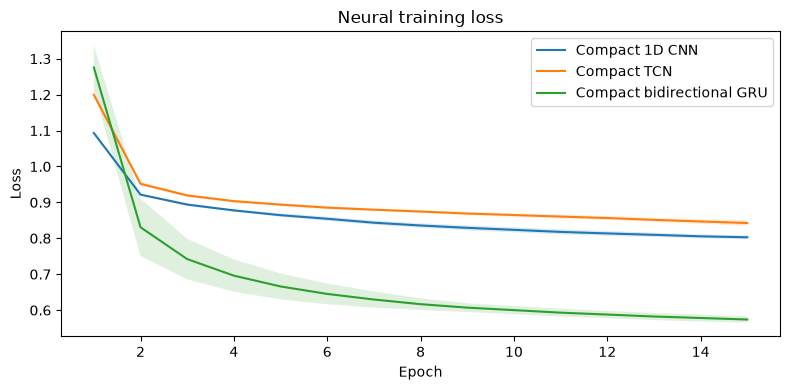

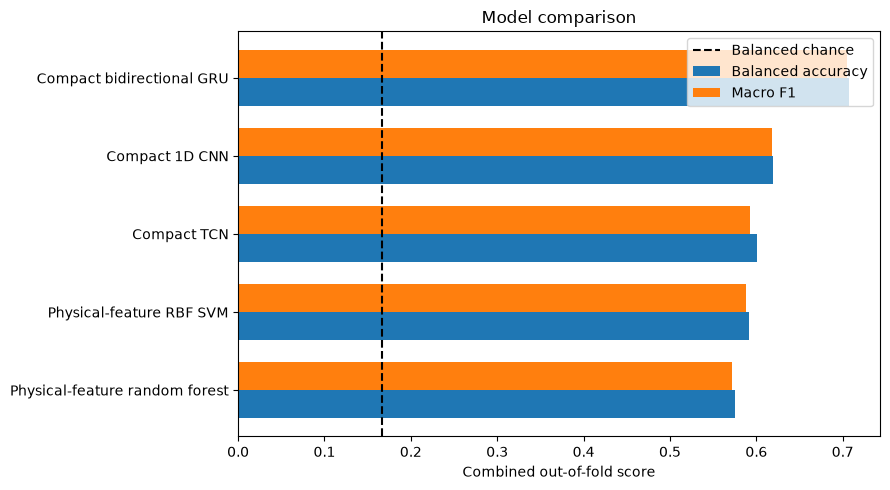

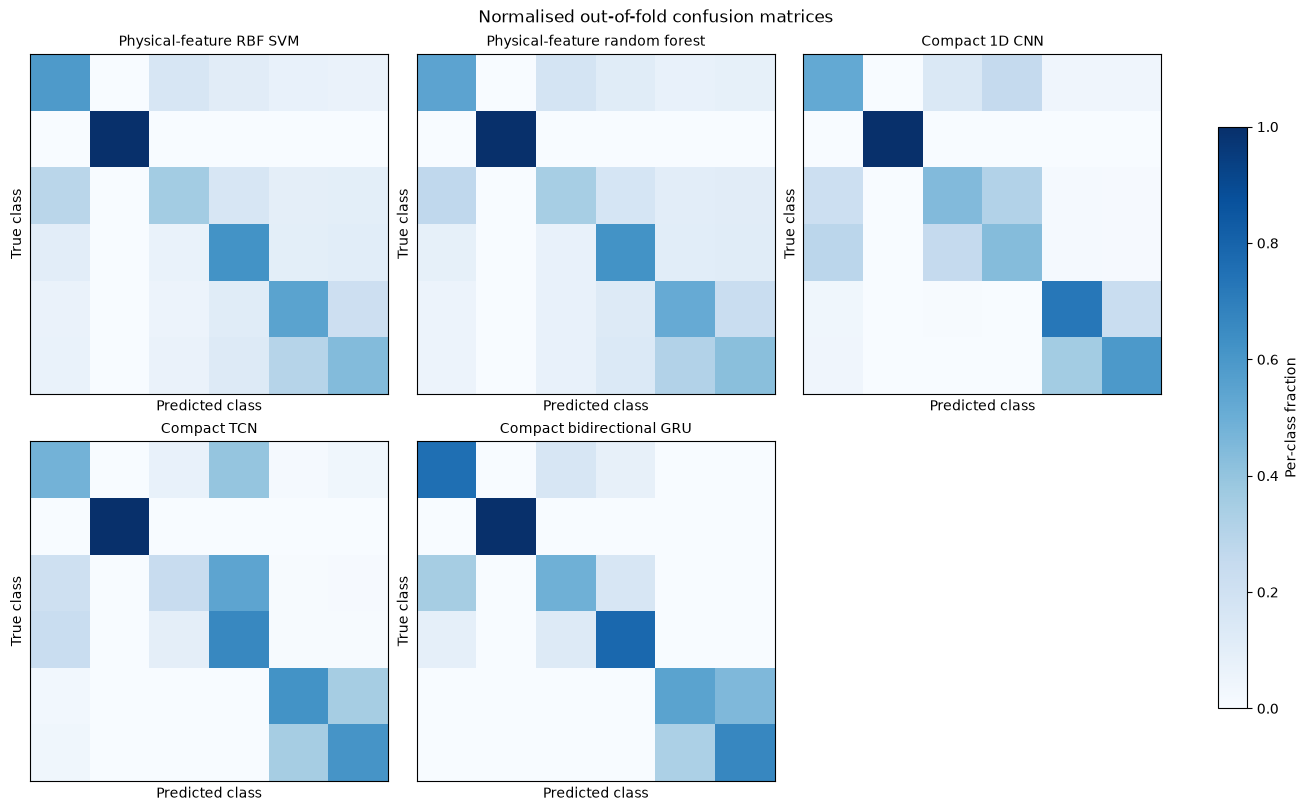

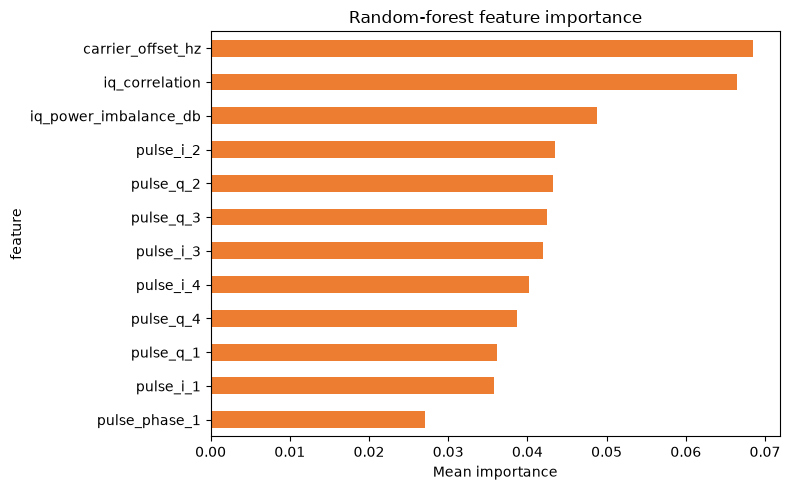

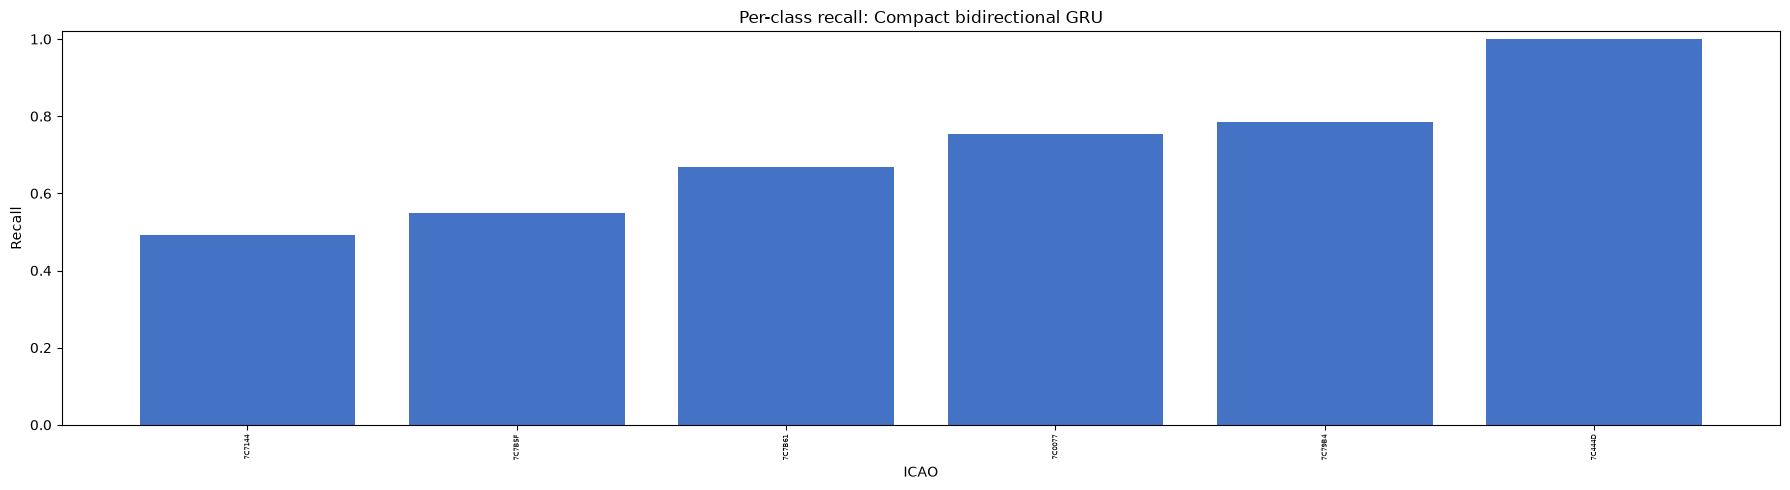

In [14]:
neural_models = ["preamble_cnn", "preamble_tcn", "preamble_gru_rnn"]
epochs = np.arange(1, CONFIG["epochs"] + 1)
fig, axis = plt.subplots(figsize=(8, 4))
for experiment in neural_models:
    histories = np.stack([training_histories[(experiment, fold)] for fold in range(1, n_splits + 1)])
    mean = histories.mean(axis=0)
    std = histories.std(axis=0)
    axis.plot(epochs, mean, label=MODEL_NAMES[experiment])
    axis.fill_between(epochs, mean - std, mean + std, alpha=0.15)
axis.set(title="Neural training loss", xlabel="Epoch", ylabel="Loss")
axis.legend()
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "training_loss.png", dpi=180, bbox_inches="tight")
plt.show()

plot_data = aggregate_results.sort_values("oof_balanced_accuracy")
positions = np.arange(len(plot_data))
fig, axis = plt.subplots(figsize=(9, 5))
axis.barh(positions - 0.18, plot_data["oof_balanced_accuracy"], 0.36, label="Balanced accuracy")
axis.barh(positions + 0.18, plot_data["oof_macro_f1"], 0.36, label="Macro F1")
axis.axvline(1 / len(class_names), color="black", linestyle="--", label="Balanced chance")
axis.set_yticks(positions, plot_data["model"])
axis.set(title="Model comparison", xlabel="Combined out-of-fold score")
axis.legend()
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
for axis, experiment in zip(axes.ravel(), MODEL_ORDER):
    subset = predictions[predictions["experiment"] == experiment]
    matrix = confusion_matrix(
        subset["true_class"], subset["predicted_class"], labels=class_names, normalize="true"
    )
    image = axis.imshow(matrix, vmin=0, vmax=1, aspect="auto", cmap="Blues")
    axis.set_title(MODEL_NAMES[experiment], fontsize=10)
    axis.set(xlabel="Predicted class", ylabel="True class")
    axis.set_xticks([])
    axis.set_yticks([])
axes.ravel()[-1].axis("off")
fig.colorbar(image, ax=axes.ravel()[:5].tolist(), label="Per-class fraction", shrink=0.8)
fig.suptitle("Normalised out-of-fold confusion matrices")
fig.savefig(CONFIG["figure_dir"] / "confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

importance = feature_importance.groupby("feature")["importance"].mean().nlargest(12).sort_values()
fig, axis = plt.subplots(figsize=(8, 5))
importance.plot(kind="barh", ax=axis, color="#ED7D31")
axis.set(title="Random-forest feature importance", xlabel="Mean importance")
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()

best_recall = class_recall[class_recall["experiment"] == best_experiment].sort_values("recall")
fig, axis = plt.subplots(figsize=(18, 5))
axis.bar(best_recall["icao"], best_recall["recall"], color="#4472C4")
axis.set(title=f"Per-class recall: {best_model}", xlabel="ICAO", ylabel="Recall", ylim=(0, 1.02))
axis.tick_params(axis="x", rotation=90, labelsize=5)
fig.tight_layout()
fig.savefig(CONFIG["figure_dir"] / "per_class_recall.png", dpi=180, bbox_inches="tight")
plt.show()


## Save


In [15]:
output_dir = CONFIG["output_dir"]
aggregate_results.to_csv(output_dir / "aggregate_results.csv", index=False)
fold_results.to_csv(output_dir / "fold_results.csv", index=False)
predictions.to_csv(output_dir / "out_of_fold_predictions.csv", index=False)
fold_audit.to_csv(output_dir / "fold_audit.csv", index=False)
model_sizes.to_csv(output_dir / "model_sizes_by_fold.csv", index=False)
feature_importance.to_csv(output_dir / "random_forest_feature_importance.csv", index=False)
class_recall.to_csv(output_dir / "per_class_recall.csv", index=False)
cross_day_results.to_csv(output_dir / "cross_day_performance.csv", index=False)
preprocessing_audit.to_csv(output_dir / "preprocessing_audit.csv", index=False)
capture_audit.to_csv(output_dir / "capture_file_audit.csv", index=False)
file_day_counts.to_csv(output_dir / "capture_file_day_counts.csv", index=False)
day_counts.to_csv(output_dir / "day_counts.csv", index=False)
aircraft_counts.to_csv(output_dir / "aircraft_counts.csv")
aircraft_file_counts.to_csv(output_dir / "aircraft_file_counts.csv")
aircraft_day_counts.to_csv(output_dir / "aircraft_day_counts.csv")
repeated_payload_summary.to_csv(output_dir / "repeated_payload_summary.csv", index=False)

assignments = model_metadata.copy()
assignments["validation_fold"] = -1
for fold_number, (_, val_index) in enumerate(folds, 1):
    assignments.loc[val_index, "validation_fold"] = fold_number
assignments.to_csv(output_dir / "fold_assignments.csv", index=False)

model_input_audit = pd.DataFrame([{
    "representation": "physical features", "shape": "33",
    "source_samples": "0-79", "payload_samples": 0,
    "capture_hash_verified": True,
}, {
    "representation": "I/Q sequence", "shape": "2x80",
    "source_samples": "0-79", "payload_samples": 0,
    "capture_hash_verified": True,
}])
model_input_audit.to_csv(output_dir / "model_input_audit.csv", index=False)

summary = {
    "capture_files": [path.name for path in files],
    "total_records": int(len(records)),
    "crc_valid_records": int(len(valid_records)),
    "embedded_calendar_days": sorted(records["capture_day"].unique()),
    "total_icao_classes": int(valid_records["icao"].nunique()),
    "num_classes": CONFIG["num_classes"],
    "samples_per_class": CONFIG["samples_per_class"],
    "selected_icaos": class_names,
    "retained_classes": int(len(class_names)),
    "retained_records": int(len(selected)),
    "smallest_retained_class": smallest_class,
    "smallest_retained_count": int(retained_counts.min()),
    "largest_retained_class": largest_class,
    "largest_retained_count": int(retained_counts.max()),
    "aircraft_on_multiple_days": int(days_per_aircraft.gt(1).sum()),
    "folds": int(n_splits),
    "best_model": best_model,
}
with (output_dir / "dataset_summary.json").open("w") as stream:
    json.dump(summary, stream, indent=2)
with (output_dir / "experiment_config.json").open("w") as stream:
    json.dump({key: str(value) if isinstance(value, Path) else value for key, value in CONFIG.items()}, stream, indent=2)

expected_files = {path.name for path in CONFIG["data_dir"].glob(CONFIG["file_pattern"])}
assert expected_files == set(capture_audit["capture_file"])
assert model_input_audit["payload_samples"].eq(0).all()
assert fold_audit["record_overlap"].eq(0).all()
assert preprocessing_audit["fit_scope"].eq("training fold only").all()
for experiment in MODEL_ORDER:
    subset = predictions[predictions["experiment"] == experiment]
    assert len(subset) == len(selected)
    assert subset["record_index"].nunique() == len(selected)
print("Saved:", output_dir.resolve())
print("Verification passed")


Saved: /Users/calebrodgers/Desktop/ml/An-Investigation-on-Spectrum-Awareness-using-UltraScale-RFSoC-Technology/analysis/notebooks/results/20261019_adsb_specific_transmitter_mawson_lakes_class_balanced_HARDWARE_DETECTION_6x30000
Verification passed
